# Tarefa 1: caixeiro viajante com Têmpera Simulada e Algoritmo Genético

Mário Cordeiro Júnior e André F. Maccarini

Queremos visitar todas as cidades uma vez e voltar ao início, procurando uma rota de menor custo. Vamos comparar duas formas de fazer isso: mudar uma rota por vez, com Têmpera Simulada (TS), e trabalhar com várias rotas, com Algoritmo Genético (AG).

Esta é a versão com cruzamento ordenado OX e seleção por torneio, como no artigo que acompanha este notebook.

O código está inteiro neste notebook. Usamos Python, NumPy, pandas e Matplotlib, sem biblioteca de otimização pronta. Para executar, abra no Jupyter e rode as células em ordem. As saídas ficam salvas para permitir a leitura sem executar.

Primeiro conferimos um exemplo de cinco cidades. Depois executamos os casos de 20, 50 e 100 cidades. As tabelas deste notebook vêm dessas execuções. O artigo que acompanha este notebook contém registros de outro protocolo; não tratamos seus números históricos como se tivessem sido reproduzidos aqui.

## 1. O que estamos modelando

Nosso programa planeja uma ordem de visitas. Ele conhece as distâncias e usa essas informações para tentar melhorar a rota.

| Parte do PEAS | Nossa escolha |
|---|---|
| Desempenho | Entregar uma rota válida e procurar menor distância total. |
| Ambiente | Um conjunto fixo de cidades e suas distâncias. |
| Ações | Propor rotas, trocar cidades e combinar rotas no AG. |
| Informações disponíveis | Coordenadas, matriz de distâncias e custos das rotas. |

Tratamos as distâncias como conhecidas e fixas. Para uma rota definida, o custo também é definido. Os sorteios pertencem aos algoritmos; não fazem a distância mudar. As rotas possíveis formam um conjunto finito. A população do AG não representa vários motoristas disputando o trajeto.

A modelagem tem quatro partes: o problema de visitar cidades; a decisão de usar um circuito com todas elas; a representação por lista e matriz; e o código que aplica TS ou AG. Não incluímos trânsito, capacidade do veículo ou janelas de entrega.

## 2. A rota e seu custo

Representamos a rota por uma lista que contém cada cidade uma vez. Isso é uma permutação. A matriz guarda o custo de ir de uma cidade a outra.

A fórmula soma cada trecho e também a volta da última cidade à primeira:

$$f(P) = \sum_{i=0}^{n-2} c_{P(i),P(i+1)} + c_{P(n-1),P(0)}.$$

Por exemplo, `[0, 2, 1, 3]` representa a volta `0 → 2 → 1 → 3 → 0`. Já `[0, 2, 2, 3]` é inválida: repete uma cidade e deixa outra de fora. Um custo baixo não compensa uma rota inválida.

Vamos começar com cinco cidades, para conseguir conferir as contas à mão.

In [1]:
import math
import random
import heapq
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixamos os sorteios; o tempo de execução ainda pode variar.
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Definindo 5 cidades com coordenadas cartesianas controladas
# A=(0,0), B=(0,300), C=(400,300), D=(400,0), E=(200,150)
cidades_brinquedo = [
    (0, 0),       # Cidade 0: A
    (0, 300),     # Cidade 1: B
    (400, 300),   # Cidade 2: C
    (400, 0),     # Cidade 3: D
    (200, 150)    # Cidade 4: E (ponto central)
]
nomes_cidades = ['A', 'B', 'C', 'D', 'E']

def gerar_matriz_distancias(cidades):
    """Calcula a matriz euclidiana de distâncias simétricas entre todas as cidades."""
    n = len(cidades)
    matriz = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            d = math.hypot(cidades[i][0] - cidades[j][0], cidades[i][1] - cidades[j][1])
            matriz[i][j] = d
            matriz[j][i] = d
    return matriz

matriz_brinquedo = gerar_matriz_distancias(cidades_brinquedo)
print("Matriz de Distâncias do Exemplo Brinquedo (5 Cidades):")
for i, linha in enumerate(matriz_brinquedo):
    vals = "  ".join([f"{v:6.1f}" for v in linha])
    print(f"  {nomes_cidades[i]}: [{vals}]")



Matriz de Distâncias do Exemplo Brinquedo (5 Cidades):
  A: [   0.0   300.0   500.0   400.0   250.0]
  B: [ 300.0     0.0   400.0   500.0   250.0]
  C: [ 500.0   400.0     0.0   300.0   250.0]
  D: [ 400.0   500.0   300.0     0.0   250.0]
  E: [ 250.0   250.0   250.0   250.0     0.0]


### Conferindo a soma à mão

Na rota `A → B → C → D → E → A`, temos:

- De A a B: 300.
- De B a C: 400.
- De C a D: 300.
- De D a E: $\sqrt{200^2+150^2}=250$.
- De E a A: 250.

O total esperado é `300 + 400 + 300 + 250 + 250 = 1500`. A volta ao início faz parte dessa conta.

In [2]:
def calcular_custo_total(rota, matriz_dist):
    """Calcula a soma das distancias ao longo da rota fechada e o retorno a origem."""
    n = len(rota)
    custo = matriz_dist[rota[-1], rota[0]] # retorno a primeira cidade
    for i in range(n - 1):
        custo += matriz_dist[rota[i], rota[i + 1]]
    return custo

def formatar_rota(rota, nomes):
    """Exibe a rota com os nomes legíveis das cidades."""
    return " -> ".join([nomes[c] for c in rota]) + f" -> {nomes[rota[0]]}"

rota_teste = [0, 1, 2, 3, 4] # A -> B -> C -> D -> E -> A
custo_obtido = calcular_custo_total(rota_teste, matriz_brinquedo)

print(f"Rota de Teste: {formatar_rota(rota_teste, nomes_cidades)}")
print(f"Custo Calculado pelo Algoritmo: {custo_obtido:.2f}")
print(f"Custo Calculado Manualmente:    1500.00")
assert abs(custo_obtido - 1500.0) < 1e-6, "Erro no calculo do custo!"
print(">> [TESTE UNITARIO VALIDADO COM SUCESSO]")



Rota de Teste: A -> B -> C -> D -> E -> A
Custo Calculado pelo Algoritmo: 1500.00
Custo Calculado Manualmente:    1500.00
>> [TESTE UNITARIO VALIDADO COM SUCESSO]


## 3. Comparação com busca por rotas parciais

Uma busca clássica pode começar na cidade 0 e acrescentar uma cidade ainda não visitada por vez. Nesse caso, cada estado é uma rota parcial. Na TS e no AG, trabalhamos com rotas completas desde o começo.

A função abaixo tem o nome `a_star_tsp`, mas usa estimativa zero para o restante. A fila é ordenada só pelo custo já percorrido, como na busca de custo uniforme. Usar o custo percorrido não torna a busca informada: falta uma estimativa do que ainda resta.

Na revisão, corrigimos o fechamento do circuito: a volta à origem também entra na fila com seu custo. Só depois retiramos a solução completa de menor custo. No exemplo pequeno, conferimos o resultado por enumeração. Essa verificação não é uma medição de desempenho em instâncias grandes.

In [3]:
def a_star_tsp(matriz_dist):
    """Busca A* (Uniform Cost Search / Heuristica Admissivel Zero) para o PCV."""
    n = len(matriz_dist)
    # heap de prioridade: (f_score, g_custo, cidade_atual, mascara_visitadas, caminho)
    inicio = (0.0, 0.0, 0, 1 << 0, [0])
    fronteira = [inicio]
    nos_expandidos = 0
    tamanho_max_fronteira = 1
    todos_visitados = (1 << n) - 1
    
    while fronteira:
        f, g, u, mask, path = heapq.heappop(fronteira)
        nos_expandidos += 1
        
        if mask == todos_visitados:
            if u == 0 and len(path) == n + 1:
                return path, g, nos_expandidos, tamanho_max_fronteira
            # A volta também entra na fila: só um circuito fechado pode ser a resposta.
            custo_fechado = g + matriz_dist[u, 0]
            heapq.heappush(fronteira, (custo_fechado, custo_fechado, 0, mask, path + [0]))
            tamanho_max_fronteira = max(tamanho_max_fronteira, len(fronteira))
            continue
            
        for v in range(n):
            if not (mask & (1 << v)):
                novo_g = g + matriz_dist[u, v]
                nova_mask = mask | (1 << v)
                heapq.heappush(fronteira, (novo_g, novo_g, v, nova_mask, path + [v]))
                
        if len(fronteira) > tamanho_max_fronteira:
            tamanho_max_fronteira = len(fronteira)
            
    return None, float('inf'), nos_expandidos, tamanho_max_fronteira

caminho_otimo_astar, custo_astar, nos_exp, max_front = a_star_tsp(matriz_brinquedo)
print("Resultado da busca com estimativa zero no exemplo de 5 cidades:")
print(f"  Rota encontrada: {formatar_rota(caminho_otimo_astar[:-1], nomes_cidades)}")
print(f"  Custo encontrado: {custo_astar:.2f}")
print(f"  Nós Expandidos: {nos_exp}")
print(f"  Tamanho Máximo da Fronteira na Memória: {max_front} nós")



Resultado da busca com estimativa zero no exemplo de 5 cidades:
  Rota encontrada: A -> B -> C -> D -> E -> A
  Custo encontrado: 1500.00
  Nós Expandidos: 61
  Tamanho Máximo da Fronteira na Memória: 24 nós


### O que muda na memória

A busca por rotas parciais guarda candidatos na fila, que pode crescer muito. A TS guarda uma rota atual e a melhor encontrada. O AG guarda uma população.

Mas a memória total também inclui a matriz de distâncias e os históricos dos gráficos. Por isso, não basta dizer que todo o programa da TS usa apenas uma lista. A matriz tem `n × n` posições, cada rota tem `n`, e uma população com `P` rotas tem `P × n` posições.

Não medimos aqui um número de cidades a partir do qual A* se torna impossível. Isso depende da implementação, da heurística e dos recursos disponíveis. Nas execuções limitadas de TS e AG, também não temos garantia de chegar ao ótimo.

## 4. Têmpera Simulada: uma rota por vez

A TS começa com uma rota completa. Propõe uma vizinha trocando duas cidades e calcula a diferença de custo:

$$\Delta = custo(nova)-custo(atual).$$

Se a proposta melhora ou empata, ela é aceita. Se piora, pode ser aceita com probabilidade $e^{-\Delta/T}$. A temperatura $T$ controla essa chance e diminui durante a execução.

Aceitar uma piora pode ajudar a continuar a busca, mas não garante escapar de qualquer situação ruim.

### A troca mantém a rota válida

Trocar duas posições só muda a ordem. As cidades continuam presentes, sem repetição. Abaixo conferimos a rota antes e depois da troca.

In [4]:
def trocar_cidades(rota, i, j):
    """Gera um vizinho trocando as posicoes i e j no vetor de permutacao."""
    nova_rota = list(rota)
    nova_rota[i], nova_rota[j] = nova_rota[j], nova_rota[i]
    return nova_rota

rota_original = [0, 1, 2, 3, 4] # A -> B -> C -> D -> E -> A
rota_vizinha = trocar_cidades(rota_original, 1, 4) # Troca B (indice 1) com E (indice 4)

custo_orig = calcular_custo_total(rota_original, matriz_brinquedo)
custo_viz = calcular_custo_total(rota_vizinha, matriz_brinquedo)
delta_calculado = custo_viz - custo_orig

print(f"Rota Original: {formatar_rota(rota_original, nomes_cidades)} | Custo: {custo_orig:.2f}")
print(f"Rota Vizinha:  {formatar_rota(rota_vizinha, nomes_cidades)} | Custo: {custo_viz:.2f}")
print(f"Delta E (Variação de Custo): {delta_calculado:+.2f}")



Rota Original: A -> B -> C -> D -> E -> A | Custo: 1500.00
Rota Vizinha:  A -> E -> C -> D -> B -> A | Custo: 1600.00
Delta E (Variação de Custo): +100.00


### Por que a temperatura muda a aceitação

Para a mesma piora, uma temperatura maior dá uma chance maior de aceitar. Quando a temperatura cai, essa chance diminui. Se a diferença é zero, a probabilidade é um: empate não é piora.

O exemplo abaixo usa uma piora de 100 e compara temperaturas. O sorteio decide se aquela proposta específica é aceita.

In [5]:
def criterio_metropolis(delta_e, temperatura, rng=None):
    if rng is None:
        rng = random.Random()
    if delta_e < 0:
        return True, 1.0
    if temperatura <= 1e-9:
        return False, 0.0
    probabilidade = math.exp(-delta_e / temperatura)
    aceita = rng.random() < probabilidade
    return aceita, probabilidade

delta_piora = 100.0 # Uma rota candidata que piorou em 100 unidades
print("Simulação do Critério de Metropolis para piora fixa de Delta E = +100:")
print(f"{'Temperatura (T)':<18} | {'Probabilidade (p)':<20} | {'Comportamento do Agente':<30}")
print("-" * 75)

for T in [10000, 1000, 500, 100, 50, 10, 1]:
    _, p = criterio_metropolis(delta_piora, T)
    comportamento = "Exploração livre (quase tudo aceito)" if p > 0.8 else (
        "Equilíbrio exploração / refino" if p > 0.2 else "Refino estrito (quase nada aceito)"
    )
    print(f"T = {T:<14} | p = {p:<18.4f} | {comportamento}")



Simulação do Critério de Metropolis para piora fixa de Delta E = +100:
Temperatura (T)    | Probabilidade (p)    | Comportamento do Agente       
---------------------------------------------------------------------------
T = 10000          | p = 0.9900             | Exploração livre (quase tudo aceito)
T = 1000           | p = 0.9048             | Exploração livre (quase tudo aceito)
T = 500            | p = 0.8187             | Exploração livre (quase tudo aceito)
T = 100            | p = 0.3679             | Equilíbrio exploração / refino
T = 50             | p = 0.1353             | Refino estrito (quase nada aceito)
T = 10             | p = 0.0000             | Refino estrito (quase nada aceito)
T = 1              | p = 0.0000             | Refino estrito (quase nada aceito)


### Formas de reduzir a temperatura

Comparamos as quatro expressões usadas nesta versão:

| Forma | Próxima temperatura |
|---|---|
| Linear | $T_k=T_{k-1}-\alpha$ |
| Geométrica | $T_k=T_{k-1}\alpha$ |
| Exponencial | $T_k=T_{k-1}e^{-\alpha}$ |
| Logarítmica | $T_k=T_0/(1+\alpha\ln(1+k))$ |

São formas diferentes de controlar a busca. Um gráfico da temperatura não mostra sozinho qual rota será melhor. Na forma logarítmica desta versão usamos $T_0$ na fórmula; isso difere de dividir a temperatura anterior repetidamente.

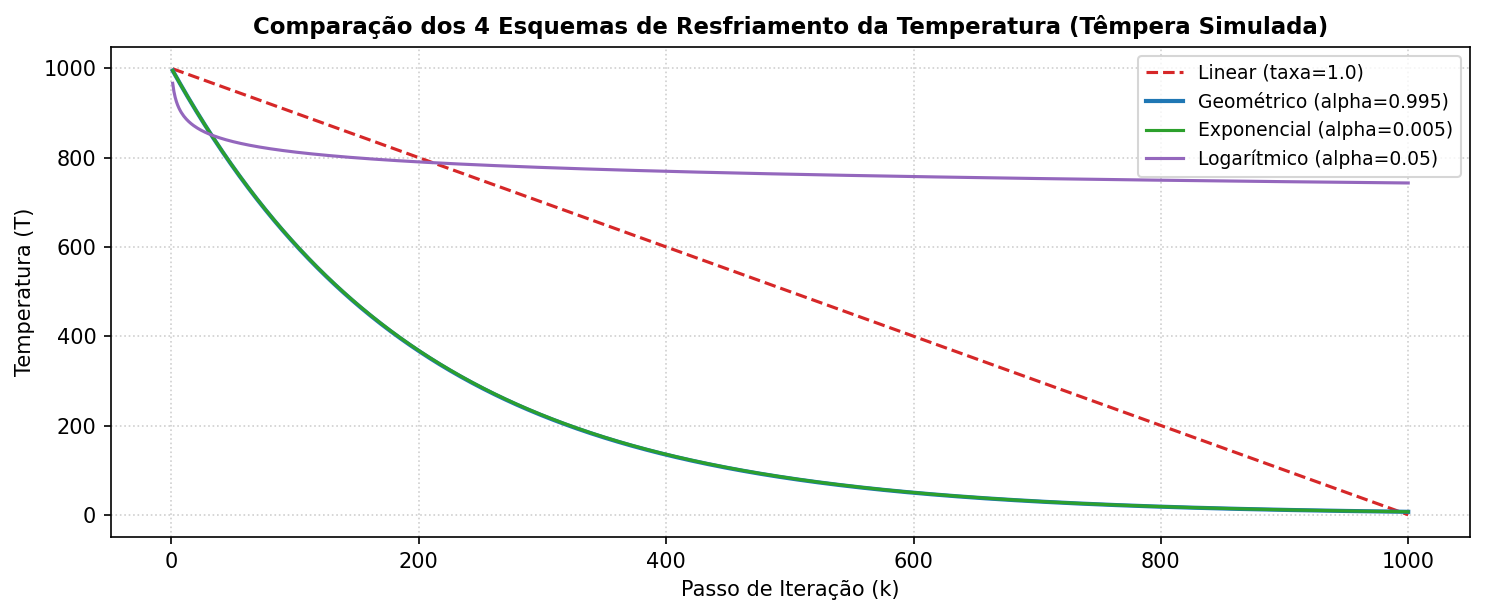

In [6]:
passos = np.arange(1, 1001)
T0 = 1000.0

# Curvas analiticas de resfriamento
temp_linear = np.maximum(0.01, T0 - passos * 1.0)
temp_geom = T0 * (0.995 ** passos)
temp_expo = T0 * np.exp(-0.005 * passos)
temp_log = T0 / (1.0 + 0.05 * np.log(1.0 + passos))

plt.figure(figsize=(10, 4.2), dpi=150)
plt.plot(passos, temp_linear, label='Linear (taxa=1.0)', color='tab:red', linestyle='--')
plt.plot(passos, temp_geom, label='Geométrico (alpha=0.995)', color='tab:blue', linewidth=2)
plt.plot(passos, temp_expo, label='Exponencial (alpha=0.005)', color='tab:green')
plt.plot(passos, temp_log, label='Logarítmico (alpha=0.05)', color='tab:purple')

plt.title('Comparação dos 4 Esquemas de Resfriamento da Temperatura (Têmpera Simulada)', fontsize=11, fontweight='bold')
plt.xlabel('Passo de Iteração (k)', fontsize=10)
plt.ylabel('Temperatura (T)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()



### Guardando a melhor rota

A TS aceita algumas pioras. Por isso, a última rota pode ser pior que uma rota visitada antes. Guardamos uma cópia da melhor encontrada e a devolvemos no fim.

O código calcula a diferença da troca olhando as arestas afetadas, sem somar o circuito inteiro a cada proposta. Mesmo assim, conferimos essa diferença contra a soma completa no final do notebook.

O histórico começa com a rota inicial. Então, a quantidade de propostas é `len(historico) - 1`. A parada ocorre pela temperatura mínima ou pelo limite de passos do código.

In [7]:
def delta_swap(rota, i, j, matriz_dist):
    """Calcula a diferenca de custo delta da troca de duas cidades em O(1)."""
    n = len(rota)
    if i == j: return 0.0
    if i > j: i, j = j, i
    i_prev, i_next = (i - 1) % n, (i + 1) % n
    j_prev, j_next = (j - 1) % n, (j + 1) % n
    if j == i + 1 or (i == 0 and j == n - 1):
        if i == 0 and j == n - 1:
            u, v = j, i
            u_prev, v_next = (u - 1) % n, (v + 1) % n
            return (matriz_dist[rota[u_prev], rota[v]] + matriz_dist[rota[u], rota[v_next]] -
                    matriz_dist[rota[u_prev], rota[u]] - matriz_dist[rota[v], rota[v_next]])
        else:
            return (matriz_dist[rota[i_prev], rota[j]] + matriz_dist[rota[i], rota[j_next]] -
                    matriz_dist[rota[i_prev], rota[i]] - matriz_dist[rota[j], rota[j_next]])
    else:
        return (matriz_dist[rota[i_prev], rota[j]] + matriz_dist[rota[j], rota[i_next]] +
                matriz_dist[rota[j_prev], rota[i]] + matriz_dist[rota[i], rota[j_next]] -
                matriz_dist[rota[i_prev], rota[i]] - matriz_dist[rota[i], rota[i_next]] -
                matriz_dist[rota[j_prev], rota[j]] - matriz_dist[rota[j], rota[j_next]])

def tempera_simulada(cidades, matriz_dist, temp_inicial=1000.0, temp_min=0.01, taxa=0.99, esquema='geometrico', seed=42):
    rng = random.Random(seed)
    n = len(cidades)
    
    # 1. Estado inicial aleatorio
    rota_atual = list(range(n))
    rng.shuffle(rota_atual)
    custo_atual = calcular_custo_total(rota_atual, matriz_dist)
    
    melhor_rota = list(rota_atual)
    melhor_custo = custo_atual
    
    T = float(temp_inicial)
    k = 1
    historico_custos = [melhor_custo]
    
    while T > temp_min and k < 10000:
        # 2. Gerar vizinho swap com delta O(1)
        i, j = rng.sample(range(n), 2)
        delta_e = delta_swap(rota_atual, i, j, matriz_dist)
        
        # 3. Criterio de Metropolis
        aceita, _ = criterio_metropolis(delta_e, T, rng)
        if aceita:
            rota_atual[i], rota_atual[j] = rota_atual[j], rota_atual[i]
            custo_atual += delta_e
            if custo_atual < melhor_custo:
                melhor_custo = custo_atual
                melhor_rota = list(rota_atual)
                
        # 4. Resfriamento
        if esquema == 'geometrico':
            T *= taxa
        elif esquema == 'linear':
            T -= taxa
        elif esquema == 'exponencial':
            T *= math.exp(-taxa)
        elif esquema == 'logaritmico':
            T = temp_inicial / (1.0 + taxa * math.log(1.0 + k))
            
        k += 1
        historico_custos.append(melhor_custo)
        
    return melhor_rota, melhor_custo, historico_custos

# Executando no exemplo brinquedo de 5 cidades
melhor_rota_ts, melhor_custo_ts, hist_ts = tempera_simulada(
    cidades_brinquedo, matriz_brinquedo, temp_inicial=500.0, temp_min=0.01, taxa=0.98, seed=42
)
print("Resultado da Têmpera Simulada no Problema Brinquedo:")
print(f"  Melhor Rota Encontrada: {formatar_rota(melhor_rota_ts, nomes_cidades)}")
print(f"  Melhor custo encontrado: {melhor_custo_ts:.2f}")
print(f"  Propostas realizadas: {len(hist_ts) - 1}")



Resultado da Têmpera Simulada no Problema Brinquedo:
  Melhor Rota Encontrada: A -> B -> C -> D -> E -> A
  Melhor custo encontrado: 1500.00
  Propostas realizadas: 536


## 5. Algoritmo Genético: várias rotas

No AG, cada indivíduo é uma rota e a população é um conjunto dessas rotas. Fazemos seleção, cruzamento e mutação para produzir a próxima geração.

Aqui usamos torneio: sorteamos três candidatos e escolhemos o de menor custo. O cruzamento é o ordenado, chamado OX. A mutação troca duas cidades. O elitismo copia a melhor rota para a geração seguinte.

Essas escolhas são desta implementação.

### População inicial e avaliação

Criamos rotas por embaralhamento e calculamos seus custos. A aptidão inversa mostrada no exemplo aumenta quando o custo diminui. No algoritmo completo abaixo, o torneio compara diretamente os custos.

In [8]:
def criar_populacao_inicial(tam_pop, num_cidades, rng):
    populacao = []
    for _ in range(tam_pop):
        ind = list(range(num_cidades))
        rng.shuffle(ind)
        populacao.append(ind)
    return populacao

def calcular_aptidao(rota, matriz_dist):
    custo = calcular_custo_total(rota, matriz_dist)
    return 1.0 / custo if custo > 0 else 1e9

rng_teste = random.Random(42)
pop_teste = criar_populacao_inicial(tam_pop=4, num_cidades=5, rng=rng_teste)

print("Amostra de População Inicial (4 Indivíduos no Exemplo Brinquedo):")
for i, ind in enumerate(pop_teste):
    c = calcular_custo_total(ind, matriz_brinquedo)
    fit = calcular_aptidao(ind, matriz_brinquedo)
    print(f"  Indivíduo {i+1}: {formatar_rota(ind, nomes_cidades)} | Custo: {c:6.1f} | Aptidão: {fit:.6f}")



Amostra de População Inicial (4 Indivíduos no Exemplo Brinquedo):
  Indivíduo 1: D -> B -> C -> E -> A -> D | Custo: 1800.0 | Aptidão: 0.000556
  Indivíduo 2: D -> C -> A -> E -> B -> D | Custo: 1800.0 | Aptidão: 0.000556
  Indivíduo 3: D -> B -> C -> A -> E -> D | Custo: 1900.0 | Aptidão: 0.000526
  Indivíduo 4: B -> C -> D -> E -> A -> B | Custo: 1500.0 | Aptidão: 0.000667


### Escolhendo os pais por torneio

Sorteamos três indivíduos e escolhemos o de menor custo entre eles. Não significa escolher sempre o melhor da população inteira: ele pode nem ter sido sorteado.

In [9]:
def selecao_torneio(populacao, matriz_dist, k=3, rng=None):
    if rng is None:
        rng = random.Random()
    amostra_indices = rng.sample(range(len(populacao)), k)
    melhor_idx = min(amostra_indices, key=lambda idx: calcular_custo_total(populacao[idx], matriz_dist))
    return populacao[melhor_idx]

pai_selecionado = selecao_torneio(pop_teste, matriz_brinquedo, k=3, rng=rng_teste)
print(f"Vencedor do Torneio: {formatar_rota(pai_selecionado, nomes_cidades)} (Custo: {calcular_custo_total(pai_selecionado, matriz_brinquedo):.2f})")



Vencedor do Torneio: D -> C -> A -> E -> B -> D (Custo: 1800.00)


### Cruzamento OX sem repetir cidades

Um corte simples pode repetir cidades e deixar outras de fora. Para evitar isso, a versão usada aqui copia um trecho do primeiro pai e preenche os espaços com cidades do segundo, pulando as que já estão no filho.

O requisito é manter uma permutação válida. Não precisamos manter todas as cidades vizinhas como estavam nos pais. Se preservássemos toda a ordem, quase não criaríamos outra rota.

PMX também foi feito para permutações, mas usa um mapeamento entre trechos dos pais. O código abaixo usa preenchimento ordenado, não esse mapeamento.

In [10]:
def crossover_ordenado_ox_didatico(pai1, pai2, c1, c2):
    tam = len(pai1)
    filho = [None] * tam
    
    # 1. Copia o segmento do Pai 1
    filho[c1:c2] = pai1[c1:c2]
    genes_presentes = set(pai1[c1:c2])
    
    print(f"Pai 1:                     {[nomes_cidades[c] for c in pai1]}")
    print(f"Pai 2:                     {[nomes_cidades[c] for c in pai2]}")
    print(f"Pontos de corte sorteados: índices {c1} até {c2-1}")
    print(f"Segmento herdado do Pai 1: {[nomes_cidades[c] for c in pai1[c1:c2]]}")
    
    # 2. Preenche com a ordem relativa do Pai 2
    ptr_p2 = 0
    for i in range(tam):
        if filho[i] is None:
            while pai2[ptr_p2] in genes_presentes:
                ptr_p2 += 1
            filho[i] = pai2[ptr_p2]
            genes_presentes.add(pai2[ptr_p2])
            
    print(f"Filho Gerado (OX Válido):  {[nomes_cidades[c] for c in filho]}")
    assert len(set(filho)) == tam, "Erro: cidades repetidas ou ausentes no filho!"
    return filho

p1 = [0, 1, 2, 3, 4] # A, B, C, D, E
p2 = [4, 2, 0, 1, 3] # E, C, A, B, D
filho_demonstracao = crossover_ordenado_ox_didatico(p1, p2, c1=1, c2=4)



Pai 1:                     ['A', 'B', 'C', 'D', 'E']
Pai 2:                     ['E', 'C', 'A', 'B', 'D']
Pontos de corte sorteados: índices 1 até 3
Segmento herdado do Pai 1: ['B', 'C', 'D']
Filho Gerado (OX Válido):  ['E', 'B', 'C', 'D', 'A']


### Próxima geração e melhor solução

O algoritmo junta os operadores anteriores. A melhor rota é copiada para a nova geração. Os demais lugares recebem filhos, que podem passar por mutação.

Uma taxa de mutação de 0,02 significa chance de 2% por filho nesta implementação. Não é uma chance por cidade. Mudar essa interpretação mudaria o algoritmo.

Preservar a melhor rota impede perder aquele custo já encontrado. Isso não prova que seja o menor custo possível.

In [11]:
def crossover_ordenado_ox(pai1, pai2, rng):
    tam = len(pai1)
    filho = [None] * tam
    c1, c2 = sorted(rng.sample(range(tam), 2))
    filho[c1:c2] = pai1[c1:c2]
    genes_presentes = set(pai1[c1:c2])
    ptr_p2 = 0
    for i in range(tam):
        if filho[i] is None:
            while pai2[ptr_p2] in genes_presentes:
                ptr_p2 += 1
            filho[i] = pai2[ptr_p2]
            genes_presentes.add(pai2[ptr_p2])
    return filho

def mutacao_swap(ind, taxa_mutacao, rng):
    if rng.random() < taxa_mutacao:
        n = len(ind)
        i, j = rng.sample(range(n), 2)
        ind[i], ind[j] = ind[j], ind[i]
    return ind

def algoritmo_genetico(cidades, matriz_dist, tam_pop=50, num_geracoes=150, taxa_crossover=0.9, taxa_mutacao=0.05, seed=42):
    rng = random.Random(seed)
    n = len(cidades)
    
    populacao = criar_populacao_inicial(tam_pop, n, rng)
    custos = [calcular_custo_total(ind, matriz_dist) for ind in populacao]
    best_idx = int(np.argmin(custos))
    melhor_solucao = list(populacao[best_idx])
    melhor_custo = custos[best_idx]
    
    historico_custos = [melhor_custo]
    
    for gen in range(num_geracoes):
        nova_populacao = [list(melhor_solucao)] # Elitismo: preserva o melhor individuo historico
        while len(nova_populacao) < tam_pop:
            t1 = rng.sample(range(len(populacao)), 3)
            p1 = populacao[min(t1, key=lambda idx: custos[idx])]
            t2 = rng.sample(range(len(populacao)), 3)
            p2 = populacao[min(t2, key=lambda idx: custos[idx])]
            
            if rng.random() < taxa_crossover:
                filho = crossover_ordenado_ox(p1, p2, rng)
            else:
                filho = list(p1)
                
            filho = mutacao_swap(filho, taxa_mutacao, rng)
            nova_populacao.append(filho)
            
        populacao = nova_populacao
        custos = [calcular_custo_total(ind, matriz_dist) for ind in populacao]
        cur_min_idx = int(np.argmin(custos))
        if custos[cur_min_idx] < melhor_custo:
            melhor_custo = custos[cur_min_idx]
            melhor_solucao = list(populacao[cur_min_idx])
            
        historico_custos.append(melhor_custo)
        
    return melhor_solucao, melhor_custo, historico_custos

# Executando o AG no exemplo brinquedo de 5 cidades
melhor_rota_ag, melhor_custo_ag, hist_ag = algoritmo_genetico(
    cidades_brinquedo, matriz_brinquedo, tam_pop=40, num_geracoes=100, taxa_crossover=0.9, taxa_mutacao=0.05, seed=42
)
print("Resultado do Algoritmo Genético no Problema Brinquedo:")
print(f"  Melhor Rota Encontrada: {formatar_rota(melhor_rota_ag, nomes_cidades)}")
print(f"  Melhor custo encontrado: {melhor_custo_ag:.2f}")
print(f"  Gerações realizadas: {len(hist_ag) - 1}")



Resultado do Algoritmo Genético no Problema Brinquedo:
  Melhor Rota Encontrada: B -> C -> D -> E -> A -> B
  Melhor custo encontrado: 1500.00
  Gerações realizadas: 100


## 6. Comparação em 20, 50 e 100 cidades

Usamos semente 42 para gerar as coordenadas e repetir os sorteios. Mantemos os parâmetros desta versão: TS com temperatura inicial 10.000, mínima 0,1 e fator 0,995; AG com população 100, cruzamento 0,9 e mutação 0,02.

O AG faz 300 gerações para 20 cidades, 600 para 50 e 1.000 para 100. Uma geração produz vários filhos; não equivale a um passo da TS. Portanto, estes limites não dão o mesmo trabalho aos dois algoritmos.

Executamos uma vez por tamanho. Isso permite descrever essas execuções, mas não provar qual algoritmo é melhor em geral. O tempo muda conforme o computador e o momento da execução. Os custos são recalculados aqui; não copiamos para esta tabela os números do artigo.

In [12]:
def gerar_cidades_aleatorias(n, seed=42):
    rng = random.Random(seed)
    return [(rng.randint(20, 980), rng.randint(20, 980)) for _ in range(n)]

escalas = [20, 50, 100]
resultados_comparativos = []
dados_vis_20 = {}

print("Executando Bateria Comparativa (TS vs. AG)...")
for n in escalas:
    cidades = gerar_cidades_aleatorias(n, seed=42)
    matriz = gerar_matriz_distancias(cidades)
    
    # Executa Têmpera Simulada
    t0 = time.time()
    rota_ts, custo_ts, hist_ts = tempera_simulada(cidades, matriz, temp_inicial=10000, temp_min=0.1, taxa=0.995, seed=42)
    tempo_ts = time.time() - t0
    
    # Executa Algoritmo Genético
    num_ger = 300 if n == 20 else (600 if n == 50 else 1000)
    t0 = time.time()
    rota_ag, custo_ag, hist_ag = algoritmo_genetico(cidades, matriz, tam_pop=100, num_geracoes=num_ger, taxa_crossover=0.9, taxa_mutacao=0.02, seed=42)
    tempo_ag = time.time() - t0
    
    vantagem_ag = ((custo_ts - custo_ag) / custo_ts) * 100.0
    
    resultados_comparativos.append({
        "Nº Cidades": n,
        "Custo TS": round(custo_ts, 2),
        "Tempo TS (s)": round(tempo_ts, 3),
        "Custo AG": round(custo_ag, 2),
        "Tempo AG (s)": round(tempo_ag, 3),
        "Vantagem AG (%)": f"{vantagem_ag:+.2f}%"
    })
    
    if n == 20:
        dados_vis_20 = {
            "cidades": cidades,
            "rota_ts": rota_ts, "custo_ts": custo_ts, "hist_ts": hist_ts,
            "rota_ag": rota_ag, "custo_ag": custo_ag, "hist_ag": hist_ag
        }

df_comparativo = pd.DataFrame(resultados_comparativos)
print("\nTabela Comparativa de Desempenho (TS vs. AG):")
display(df_comparativo)



Executando Bateria Comparativa (TS vs. AG)...



Tabela Comparativa de Desempenho (TS vs. AG):


,Nº Cidades,Custo TS,Tempo TS (s),Custo AG,Tempo AG (s),Vantagem AG (%)
0,20,4457.77,0.008,4319.20,0.408,+3.11%
1,50,8960.84,0.018,9378.06,1.319,-4.66%
2,100,20517.95,0.008,15922.31,3.400,+22.40%


### Rotas encontradas e evolução do melhor custo

O gráfico mostra as rotas de 20 cidades e o melhor custo guardado ao longo da busca. Uma curva da melhor solução não aumenta, mesmo que a TS aceite uma piora na rota atual.

Os eixos de passos e gerações não representam a mesma quantidade de trabalho. O gráfico ajuda a acompanhar cada execução; não é uma comparação com orçamento igual.

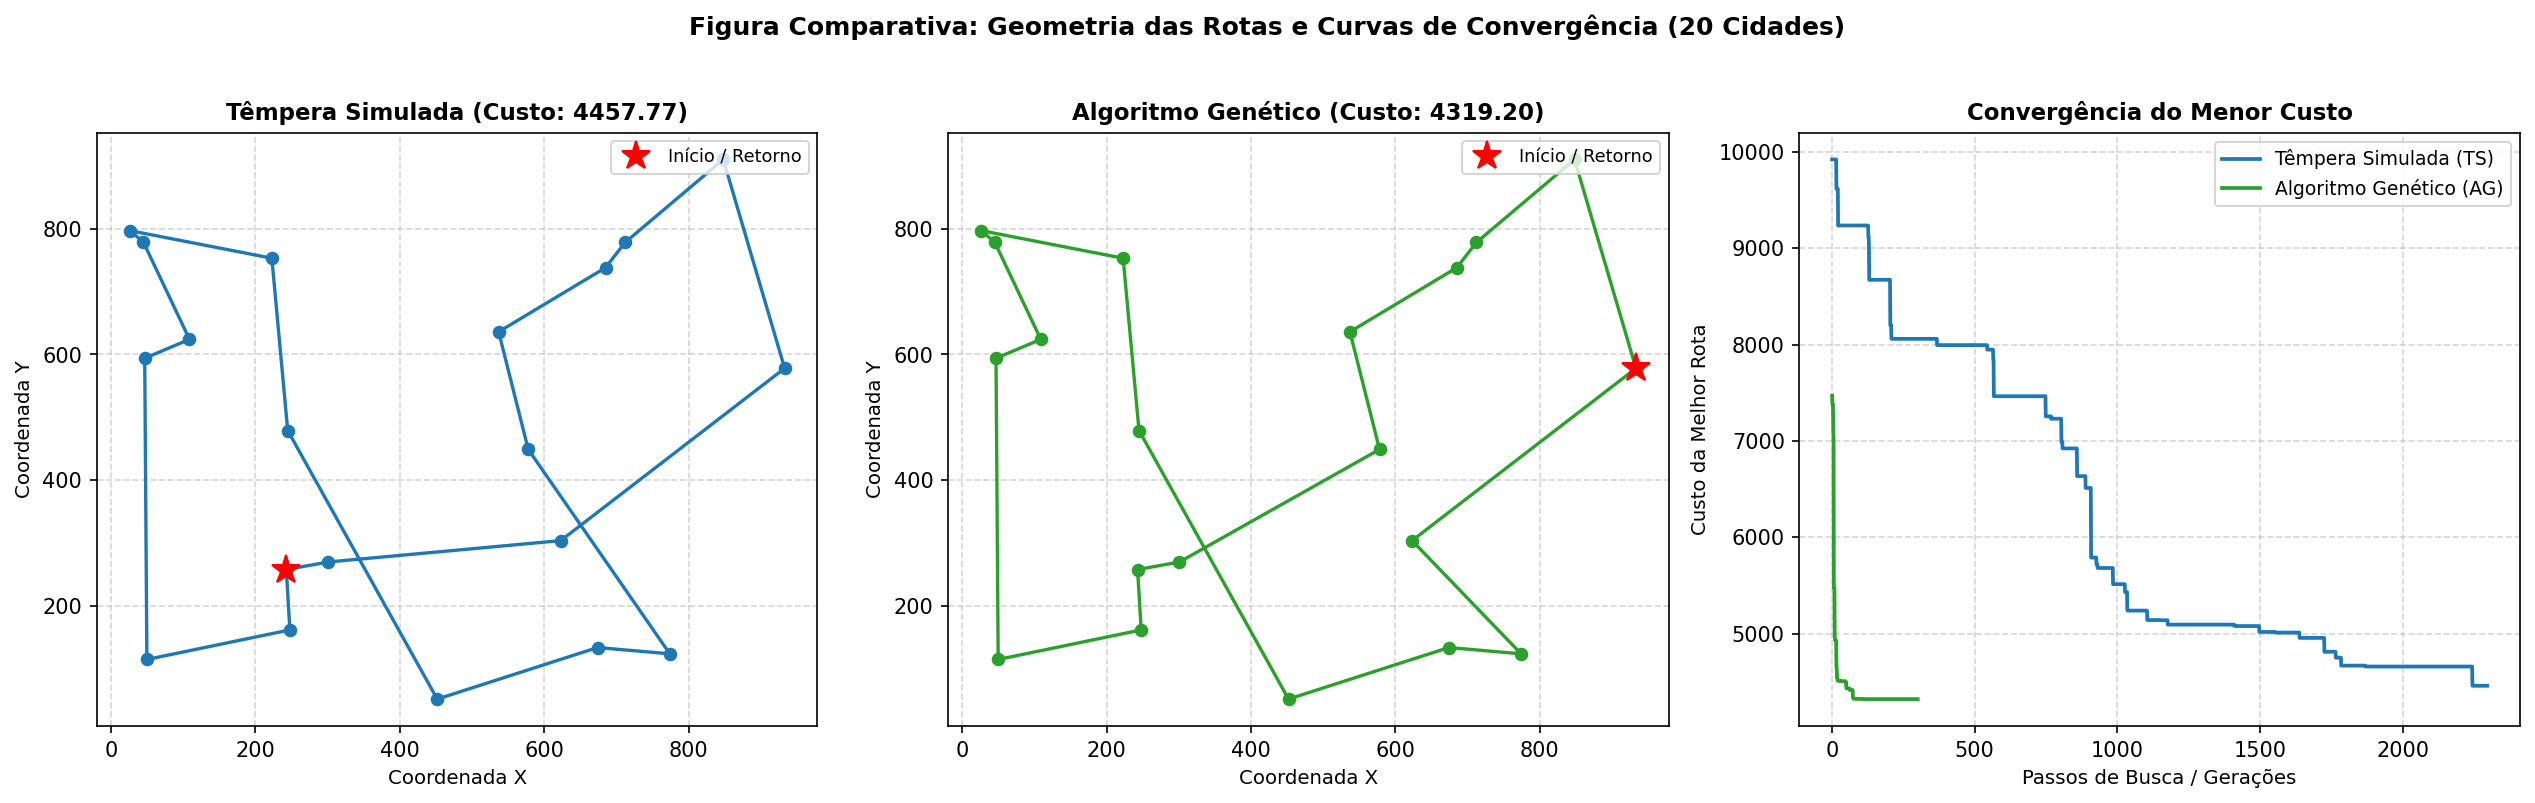

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), dpi=150)
cidades_plot = dados_vis_20["cidades"]

def desenhar_rota(ax, titulo, rota, cidades, cor):
    x = [cidades[i][0] for i in rota] + [cidades[rota[0]][0]]
    y = [cidades[i][1] for i in rota] + [cidades[rota[0]][1]]
    ax.plot(x, y, 'o-', color=cor, linewidth=1.6, markersize=5.5)
    ax.plot(x[0], y[0], 'r*', markersize=14, label='Início / Retorno')
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Coordenada X', fontsize=9.5)
    ax.set_ylabel('Coordenada Y', fontsize=9.5)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', fontsize=8.5)

desenhar_rota(axes[0], f'Têmpera Simulada (Custo: {dados_vis_20["custo_ts"]:.2f})', dados_vis_20["rota_ts"], cidades_plot, '#1f77b4')
desenhar_rota(axes[1], f'Algoritmo Genético (Custo: {dados_vis_20["custo_ag"]:.2f})', dados_vis_20["rota_ag"], cidades_plot, '#2ca02c')

# Convergência
axes[2].plot(dados_vis_20["hist_ts"], label='Têmpera Simulada (TS)', color='#1f77b4', linewidth=1.8)
axes[2].plot(dados_vis_20["hist_ag"], label='Algoritmo Genético (AG)', color='#2ca02c', linewidth=1.8)
axes[2].set_title('Convergência do Menor Custo', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Passos de Busca / Gerações', fontsize=9.5)
axes[2].set_ylabel('Custo da Melhor Rota', fontsize=9.5)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(loc='upper right', fontsize=9)

fig.suptitle('Figura Comparativa: Geometria das Rotas e Curvas de Convergência (20 Cidades)', fontsize=12, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()



## 7. O que conseguimos concluir

TS e AG usam a mesma representação por permutação e o mesmo custo de circuito. A TS mantém uma rota atual e decide se aceita uma proposta. O AG mantém uma população e decide quais pais e filhos formam a próxima geração. Por isso, a mesma troca de cidades tem papéis diferentes nas duas técnicas.

As duas dependem dos parâmetros e dos sorteios. Resfriar muito rápido pode reduzir cedo a chance de aceitar pioras. Mudar população e mutação altera a busca do AG, mas não garante melhorar. Uma curva parada também não prova que encontramos o ótimo.

Uma comparação mais justa precisa dizer quais dados foram usados, quantos custos foram avaliados, quanto tempo foi gasto e quantas execuções foram feitas. Contar gerações do AG como se fossem passos da TS esconde uma diferença de trabalho.

Nossa conclusão fica limitada aos casos e configurações executados. O artigo que acompanha este notebook é mantido como registro dos experimentos anteriores; este notebook deixa explícito o que executa e o que não reproduz.

## Apoio na revisão

Usamos o Codex, assistente de inteligência artificial da OpenAI, como apoio para reescrever as explicações, conferir a execução e organizar os arquivos. As funções e os parâmetros de TS e AG desta versão foram mantidos. Corrigimos o fechamento da rota na demonstração de busca clássica e afirmações excessivas sobre memória e garantia de ótimo na explicação, sem transformar os resultados de uma execução em uma garantia geral. O código e as saídas precisam ser lidos junto das limitações.

[Artigo em PDF](artigo.pdf) · [Dados desta execução](dados)


## 8. Conferências e dados salvos

Conferimos a validade das rotas, a soma dos custos e o cálculo da diferença de uma troca. No exemplo de cinco cidades, enumeramos todas as rotas para obter uma referência exata. Os dados exportados vêm da execução acima.


In [14]:
from pathlib import Path
from itertools import permutations
import json
pasta_dados = Path.cwd() / 'dados'
pasta_dados.mkdir(exist_ok=True)

# Conferimos o custo da troca por dois caminhos independentes.
for ordem in permutations(range(5)):
    ordem = list(ordem)
    for i in range(5):
        for j in range(i + 1, 5):
            nova = trocar_cidades(ordem, i, j)
            esperado = calcular_custo_total(nova, matriz_brinquedo) - calcular_custo_total(ordem, matriz_brinquedo)
            assert math.isclose(delta_swap(ordem, i, j, matriz_brinquedo), esperado, abs_tol=1e-8)
otimo_5 = min(calcular_custo_total([0, *r], matriz_brinquedo) for r in permutations(range(1, 5)))
assert math.isclose(custo_astar, otimo_5, abs_tol=1e-8)
assert math.isclose(calcular_custo_total(melhor_rota_ts, matriz_brinquedo), melhor_custo_ts, abs_tol=1e-7)
assert math.isclose(calcular_custo_total(melhor_rota_ag, matriz_brinquedo), melhor_custo_ag, abs_tol=1e-7)
for rota, custo in [(dados_vis_20['rota_ts'], dados_vis_20['custo_ts']), (dados_vis_20['rota_ag'], dados_vis_20['custo_ag'])]:
    assert sorted(rota) == list(range(20))
    assert math.isclose(calcular_custo_total(rota, gerar_matriz_distancias(dados_vis_20['cidades'])), custo, abs_tol=1e-7)
instancias = {str(n): gerar_cidades_aleatorias(n, seed=42) for n in escalas}
(pasta_dados/'cidades.json').write_text(json.dumps(instancias, indent=2), encoding='utf8')
(pasta_dados/'rotas_20.json').write_text(json.dumps(dados_vis_20, indent=2), encoding='utf8')
df_comparativo.to_csv(pasta_dados/'resultados.csv', index=False)
print('Custos, permutações e diferenças de troca conferidos. Referência exata para 5 cidades:', otimo_5)
print('Coordenadas, rotas de 20 cidades e tabela salvas na pasta dados.')


Custos, permutações e diferenças de troca conferidos. Referência exata para 5 cidades: 1500.0
Coordenadas, rotas de 20 cidades e tabela salvas na pasta dados.
